# Compare to DMS estimates

Here, we compare the fitness estimates from two HIV datasets (transmitted founder viruses BG505 and BF520 originally published in Haddox 2018, re-analysed in Hong 2024) with our MPL fitness estimates from the LTEE. 

In [1]:
import pandas as pd 
import numpy as np 

from Bio import SeqIO
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/data"
out_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/out"
fig_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/figures"

## Compare protein sequences between LTEE consensus and DMS ancestor

In [3]:
#Get env sequence
consensus_path = data_path + '/ancestor_consensus.fasta'
for record in SeqIO.parse(consensus_path, "fasta"):
    consensus = record.seq

genes = pd.read_csv(data_path + '/genes.csv')
env_gene = genes[genes['genename']=='Env']
env_protein = consensus[env_gene['start'].values[0]:env_gene['end'].values[0] + 1].translate()


#Get HXB2 sequence
with open(data_path + '/DMS/HXB2_env_protein_sequence.txt', 'r') as file:
    HXB2_env_protein = "".join(file.read().split())
HXB2_env_protein_del = HXB2_env_protein[:186] + HXB2_env_protein[188:] #Positions 186, 187 were deleted

#Compare differences
differences = [chr1!=ch2 for (chr1,ch2) in zip(str(env_protein)[:-1],HXB2_env_protein_del)]

print('Mutations to HXB2 to get our env protein:\n')
print('At position 186, D is deleted')
print('At position 187, T is deleted')
for d in np.argwhere(differences):
    pos = d[0]
    if pos < 186:
        print(f'At position {pos}, {HXB2_env_protein_del[pos]} is substituted for {env_protein[pos]}')
    else:
        print(f'At position {pos+2}, {HXB2_env_protein_del[pos]} is substituted for {env_protein[pos]}')

Mutations to HXB2 to get our env protein:

At position 186, D is deleted
At position 187, T is deleted
At position 15, R is substituted for K
At position 23, M is substituted for I
At position 166, G is substituted for D
At position 181, I is substituted for V
At position 191, K is substituted for R
At position 193, T is substituted for I
At position 268, E is substituted for D
At position 274, V is substituted for A
At position 305, R is substituted for S
At position 339, N is substituted for A
At position 422, I is substituted for F
At position 428, K is substituted for E
At position 460, S is substituted for N
At position 463, E is substituted for G
At position 546, G is substituted for D
At position 624, H is substituted for N
At position 625, T is substituted for M
At position 722, T is substituted for I
At position 812, S is substituted for N
At position 832, V is substituted for L
At position 834, G is substituted for A
At position 836, C is substituted for Y


## Get MPL estimates for non-synonymous Env substitutions

In [4]:
#Get MPL data
data = pd.read_pickle(out_path + '/mutation_time_series_with_fitness.pkl')
data = data[data['muttype']=='Non-synonymous']
data = data[data['gene']=='Env']

data['env pos'] = [int(s.split(':')[0]) for s in data['details']]
data['env wt aa'] = [s.split(':')[1][0] for s in data['details']]
data['env mt aa'] = [s[-1] for s in data['details']]

#Check mutation wts match with consensus protein sequence
match = []
for i, row in data.iterrows():
    match.append(env_protein[int(row['env pos'])]==row['env wt aa'])
print(f'Percent matching = {sum(match)/len(match)*100:.1f}%')

Percent matching = 100.0%


In [5]:
#Add DMS protein position (HXB2 numbering, starts at 1, deletion of 2 at 186 in consensus)
HXB2_pos = []
for p in data['env pos']:
    if p<186:
        HXB2_pos.append(p+1)
    else:
        HXB2_pos.append(p+3) 
data['HXB2 pos'] = HXB2_pos

#Check which percentage of mutation wts match with DMS HXB2 protein sequence
match = []
for i, row in data.iterrows():
    match.append(HXB2_env_protein[int(row['HXB2 pos'])-1] == row['env wt aa'])
print(f'Percent matching = {sum(match)/len(match)*100:.1f}%')

Percent matching = 90.9%


Not 100% since DMS ancestor was different to LTEE consensus

## Get DMS estimates and combine

In [6]:
#BG505 dataset
dms_data_bg = pd.read_csv(data_path + "/DMS/BG505.csv.gz")

#Add information from map
HXB2_map = pd.read_csv(data_path + "/DMS/BG505_to_HXB2_map.csv")
dms_data_bg = pd.merge(dms_data_bg, HXB2_map, left_on='site', right_on='original') 
dms_data_bg = dms_data_bg.drop(columns=['original','N-glycan']).rename(columns={'new':'HXB2 pos'})
dms_data_bg = dms_data_bg[~dms_data_bg['HXB2 pos'].str.contains('[abcdefgh]', na=False, case=False)] #remove insertions
dms_data_bg['HXB2 pos'] = dms_data_bg['HXB2 pos'].astype(int)

#Combine DMS and MPL data
data_combined_bg = pd.merge(data, dms_data_bg, left_on='HXB2 pos', right_on='HXB2 pos') #same position
data_combined_bg = data_combined_bg[data_combined_bg['env mt aa'] == data_combined_bg['amino_acid']] #same mutant amino acid
data_combined_bg = data_combined_bg[data_combined_bg['env wt aa'] == data_combined_bg['wildtype']] #same wildtype amino acid


In [7]:
#BF520 dataset
dms_data_bf = pd.read_csv(data_path + "/DMS/BF520.csv.gz")

#Add information from map
HXB2_map = pd.read_csv(data_path + "/DMS/BF520_to_HXB2_map.csv")
dms_data_bf = pd.merge(dms_data_bf, HXB2_map, left_on='site', right_on='original') 
dms_data_bf = dms_data_bf.drop(columns=['original','N-glycan']).rename(columns={'new':'HXB2 pos'})
dms_data_bf = dms_data_bf[~dms_data_bf['HXB2 pos'].str.contains('[abcdefgh]', na=False, case=False)] #remove insertions
dms_data_bf['HXB2 pos'] = dms_data_bf['HXB2 pos'].astype(int)

#Combine DMS and MPL data
data_combined_bf = pd.merge(data, dms_data_bf, left_on='HXB2 pos', right_on='HXB2 pos') #same position
data_combined_bf = data_combined_bf[data_combined_bf['env mt aa'] == data_combined_bf['amino_acid']] #same mutant amino acid
data_combined_bf = data_combined_bf[data_combined_bf['env wt aa'] == data_combined_bf['wildtype']] #same wildtype amino acid

## Plot results

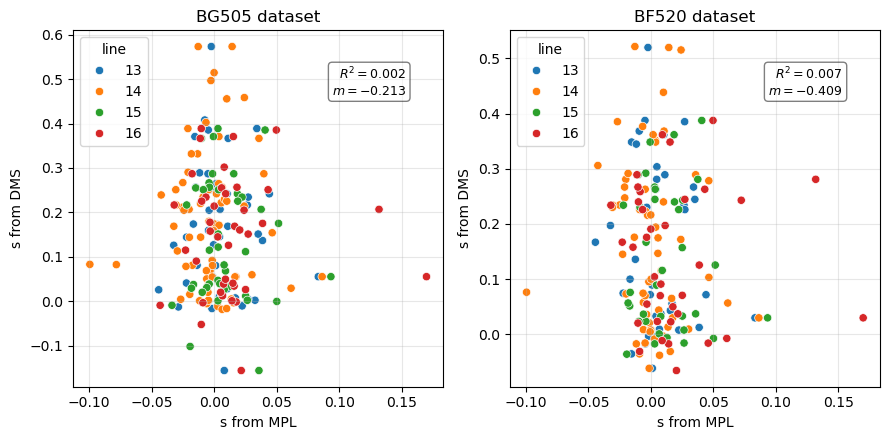

In [8]:
#Correlation of DMS and MPL estimates
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(9,4.5))
colours = ['tab:blue','tab:orange','tab:green','tab:red']

sns.scatterplot(data=data_combined_bg, ax=ax1, x='s', y='joint', hue='line',palette=colours)
m, c, r_bg, p, std_err = stats.linregress(data_combined_bg['s'], data_combined_bg['joint'])
ax1.text(0.9, 0.9, f'$R^2 = {r_bg**2:.3f}$\n$m={m:.3f}$', transform=ax1.transAxes, fontsize=9, verticalalignment='top',horizontalalignment='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
ax1.set_title('BG505 dataset')

sns.scatterplot(data=data_combined_bf, ax=ax2, x='s', y='joint', hue='line',palette=colours)
m, c, r_bf, p, std_err = stats.linregress(data_combined_bf['s'], data_combined_bf['joint'])
ax2.text(0.9, 0.9, f'$R^2 = {r_bf**2:.3f}$\n$m={m:.3f}$', transform=ax2.transAxes, fontsize=9, verticalalignment='top',horizontalalignment='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
ax2.set_title('BF520 dataset')

for ax in [ax1, ax2]:
    ax.set_xlabel('s from MPL')
    ax.set_ylabel('s from DMS')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(fig_path + f"/DMS_correlations.pdf")
plt.show()

No better correlation looking at higher frequencies, individual DMS reps or no linkage method for LTEE.

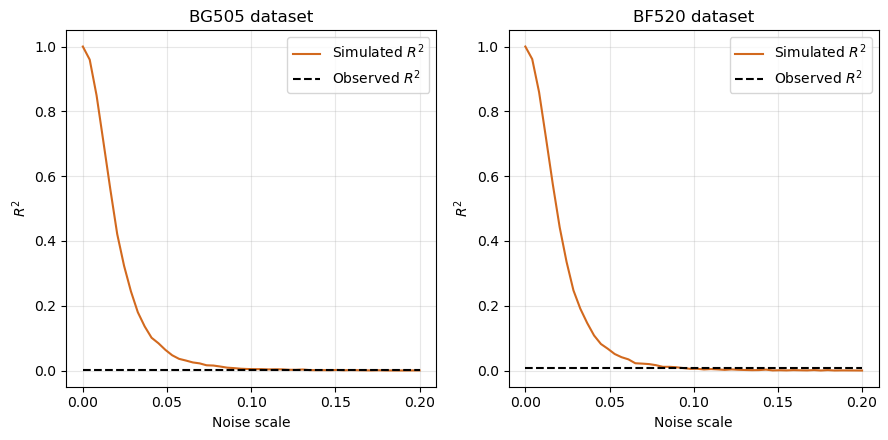

In [9]:
#What is the level of noise that would destroy true correlations? 
noise = np.linspace(0,0.2,50)
num_reps = 100

#BG505 dataset
s = data_combined_bg['s'].values
r_bg_noise = np.zeros(noise.shape[0])
for i, n in enumerate(noise):
    r_ = []
    for j in range(num_reps):
        x = s + np.random.normal(0, n, size=s.shape)
        y = s + np.random.normal(0, n, size=s.shape)
        _,_,r,_,_ = stats.linregress(x,y)
        r_.append(r)
    r_bg_noise[i] = np.mean(r_)


#BF520 dataset
s = data_combined_bf['s'].values
r_bf_noise = np.zeros(noise.shape[0])
for i, n in enumerate(noise):
    r_ = []
    for j in range(num_reps):
        x = s + np.random.normal(0, n, size=s.shape)
        y = s + np.random.normal(0, n, size=s.shape)
        _,_,r,_,_ = stats.linregress(x,y)
        r_.append(r)
    r_bf_noise[i] = np.mean(r_)

#Plot results
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(9,4.5))

ax1.plot(noise, r_bg_noise**2,label='Simulated $R^2$',color='chocolate')
ax1.plot(noise, np.zeros_like(noise) + r_bg**2, '--', color='black',label='Observed $R^2$')
ax1.set_title('BG505 dataset')

ax2.plot(noise, r_bf_noise**2,label='Simulated $R^2$',color='chocolate')
ax2.plot(noise, np.zeros_like(noise) + r_bf**2, '--', color='black',label='Observed $R^2$')
ax2.set_title('BF520 dataset')

for ax in [ax1, ax2]:
    ax.set_ylabel('$R^2$')
    ax.set_xlabel('Noise scale')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig(fig_path + f"/DMS_simulated_R2.pdf")
plt.show()

So the observed correlations are consistent with adding noise with std around 0.1 to both estimates.

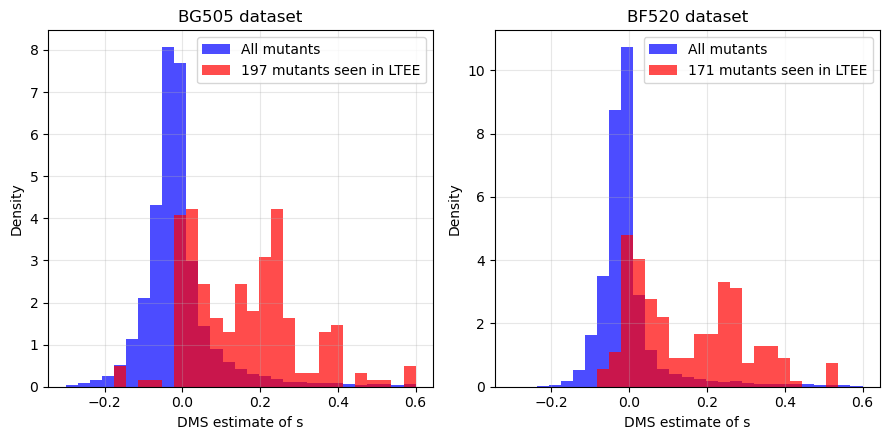

In [10]:
#DMS estimates of mutations seen in LTEE
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(9,4.5))

dms_data_bf_all = pd.read_csv(data_path + "/DMS/BF520.csv.gz")
dms_data_bg_all = pd.read_csv(data_path + "/DMS/BG505.csv.gz")

ax1.hist(dms_data_bg_all['joint'], bins=np.linspace(-0.3,0.6,30), alpha=0.7, color='blue',density=True,label='All mutants')
ax1.hist(data_combined_bg['joint'], bins=np.linspace(-0.3,0.6,30), alpha=0.7, color='red',density=True,label='197 mutants seen in LTEE')
ax1.set_title('BG505 dataset')

ax2.hist(dms_data_bf_all['joint'], bins=np.linspace(-0.3,0.6,30), alpha=0.7, color='blue',density=True,label='All mutants')
ax2.hist(data_combined_bf['joint'], bins=np.linspace(-0.3,0.6,30), alpha=0.7, color='red',density=True,label='171 mutants seen in LTEE')
ax2.set_title('BF520 dataset')

for ax in [ax1, ax2]:
    ax.set_xlabel('DMS estimate of s')
    ax.set_ylabel('Density')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(fig_path + f"/DMS_dataset_overlap.pdf")
plt.show()

In [11]:
#Percentage of positive selection coefficients
print('BG505 dataset')
print(f"Percentage positive = {(((dms_data_bg_all['joint']>0).sum())/(len((dms_data_bg_all['joint']))))*100:.2f}%")
print(f"Percentage LTEE muts positive = {(((data_combined_bg['joint']>0).sum())/(len((data_combined_bg['joint']))))*100:.2f}%")

print('BF520 dataset')
print(f"Percentage positive = {(((dms_data_bf_all['joint']>0).sum())/(len((dms_data_bf_all['joint']))))*100:.2f}%")
print(f"Percentage LTEE muts positive = {(((data_combined_bf['joint']>0).sum())/(len((data_combined_bf['joint']))))*100:.2f}%")

#Randomisation test: 
# choose a subset of the full dataset equal to the size of MPL overlap, calculate percentage positive, see if it is greater than true percent
num_tests = 10000
count_bg = 0
count_bf = 0
for i in range(num_tests):
    sample = dms_data_bg_all['joint'].sample(n=len(data_combined_bg['joint']), replace=True, random_state=i)
    if (sample > 0).sum() / len(sample) > 0.9091:
        count_bg += 1

    sample = dms_data_bf_all['joint'].sample(n=len(data_combined_bf['joint']), replace=True, random_state=i)
    if (sample > 0).sum() / len(sample) > 0.8571:
        count_bf += 1

print('\nRandomisation test:')
print(f'BG505 p-value = {count_bg/num_tests}')
print(f'BF5020 p-value = {count_bf/num_tests}')

BG505 dataset
Percentage positive = 31.08%
Percentage LTEE muts positive = 90.91%
BF520 dataset
Percentage positive = 29.06%
Percentage LTEE muts positive = 85.71%

Randomisation test:
BG505 p-value = 0.0
BF5020 p-value = 0.0


Significantly more likely for the observed mutations to have a positive DMS selection coefficient than random (p-value < 0.0001)

## Older datasets

In [12]:
#Load older datasets
bf_prefs = pd.read_csv(data_path + "/DMS/BF520_avgprefs.csv")
bg_prefs = pd.read_csv(data_path + "/DMS/BG505_avgprefs.csv")

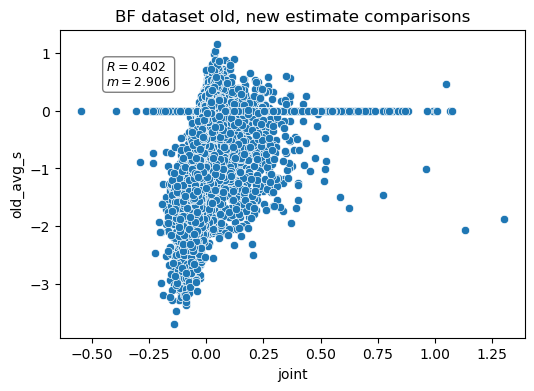

In [13]:
#Check we have the same numbering scheme: 'HXB2 pos' here, 'site' in old preferences
bf_fitnesses = []
for i,row in dms_data_bf.iterrows():
    if row['amino_acid'] == '*':
        bf_fitnesses.append(np.nan)
    else:
        aa_pref = bf_prefs.loc[bf_prefs['site']==str(row['HXB2 pos']),row['amino_acid']].values[0]
        wt_pref = bf_prefs.loc[bf_prefs['site']==str(row['HXB2 pos']),row['wildtype']].values[0]
        bf_fitnesses.append(np.log(aa_pref/wt_pref))

dms_data_bf['old_avg_s'] = bf_fitnesses

#Plot
fig, ax = plt.subplots(1,1,figsize=(6,4))
sns.scatterplot(data = dms_data_bf, x='joint', y='old_avg_s',ax=ax)
mask = ~np.isnan(dms_data_bf['old_avg_s'])
m, c, r_bg, p, std_err = stats.linregress(dms_data_bf['joint'][mask],dms_data_bf['old_avg_s'][mask])
ax.text(0.1, 0.9, f'$R = {r_bg:.3f}$\n$m={m:.3f}$', transform=ax.transAxes, fontsize=9, verticalalignment='top',horizontalalignment='left', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
plt.title('BF dataset old, new estimate comparisons')
plt.show()

In [14]:
#Add old fitness estimates
bf_fitness = []
for i,row in data_combined_bf.iterrows():
    pos = row['HXB2 pos']
    aa = row['amino_acid']
    wt_aa = row['wildtype']

    pref = bf_prefs.loc[bf_prefs['site']==str(pos),str(aa)].values[0]
    wt_pref= bf_prefs.loc[bf_prefs['site']==str(pos),str(wt_aa)].values[0]
    bf_fitness.append(np.log(pref/wt_pref))

data_combined_bf['old_rep_avg'] = bf_fitness


bg_fitness = []
for i,row in data_combined_bg.iterrows():
    pos = row['HXB2 pos']
    aa = row['amino_acid']
    wt_aa = row['wildtype']

    pref = bg_prefs.loc[bg_prefs['site']==str(pos),str(aa)].values[0]
    wt_pref= bg_prefs.loc[bg_prefs['site']==str(pos),str(wt_aa)].values[0]
    bg_fitness.append(np.log(pref/wt_pref))

data_combined_bg['old_rep_avg'] = bg_fitness

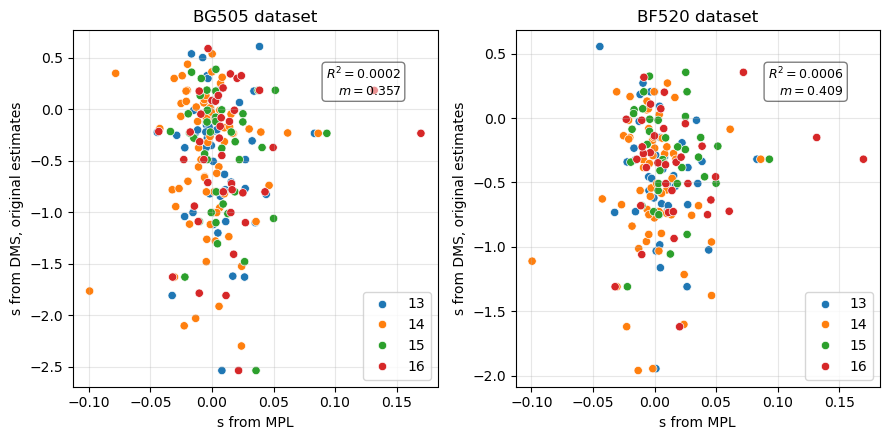

In [ ]:
#Correlation of DMS and MPL estimates
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(9,4.5))
colours = ['tab:blue','tab:orange','tab:green','tab:red']

sns.scatterplot(data=data_combined_bg, ax=ax1, x='s', y='old_rep_avg', hue='line',palette=colours)
m, c, r_bg, p, std_err = stats.linregress(data_combined_bg['s'], data_combined_bg['old_rep_avg'])
ax1.text(0.9, 0.9, f'$R^2 = {r_bg**2:.4f}$\n$m={m:.3f}$', transform=ax1.transAxes, fontsize=9, verticalalignment='top',horizontalalignment='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
ax1.set_title('BG505 dataset')

sns.scatterplot(data=data_combined_bf, ax=ax2, x='s', y='old_rep_avg', hue='line',palette=colours)
m, c, r_bf, p, std_err = stats.linregress(data_combined_bf['s'], data_combined_bf['old_rep_avg'])
ax2.text(0.9, 0.9, f'$R^2 = {r_bf**2:.4f}$\n$m={m:.3f}$', transform=ax2.transAxes, fontsize=9, verticalalignment='top',horizontalalignment='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
ax2.set_title('BF520 dataset')

for ax in [ax1, ax2]:
    ax.set_xlabel('s from MPL')
    ax.set_ylabel('s from DMS, original estimates')
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig(fig_path + f"/DMS_correlations_original_estimates.pdf")
plt.show()

## Figure 5

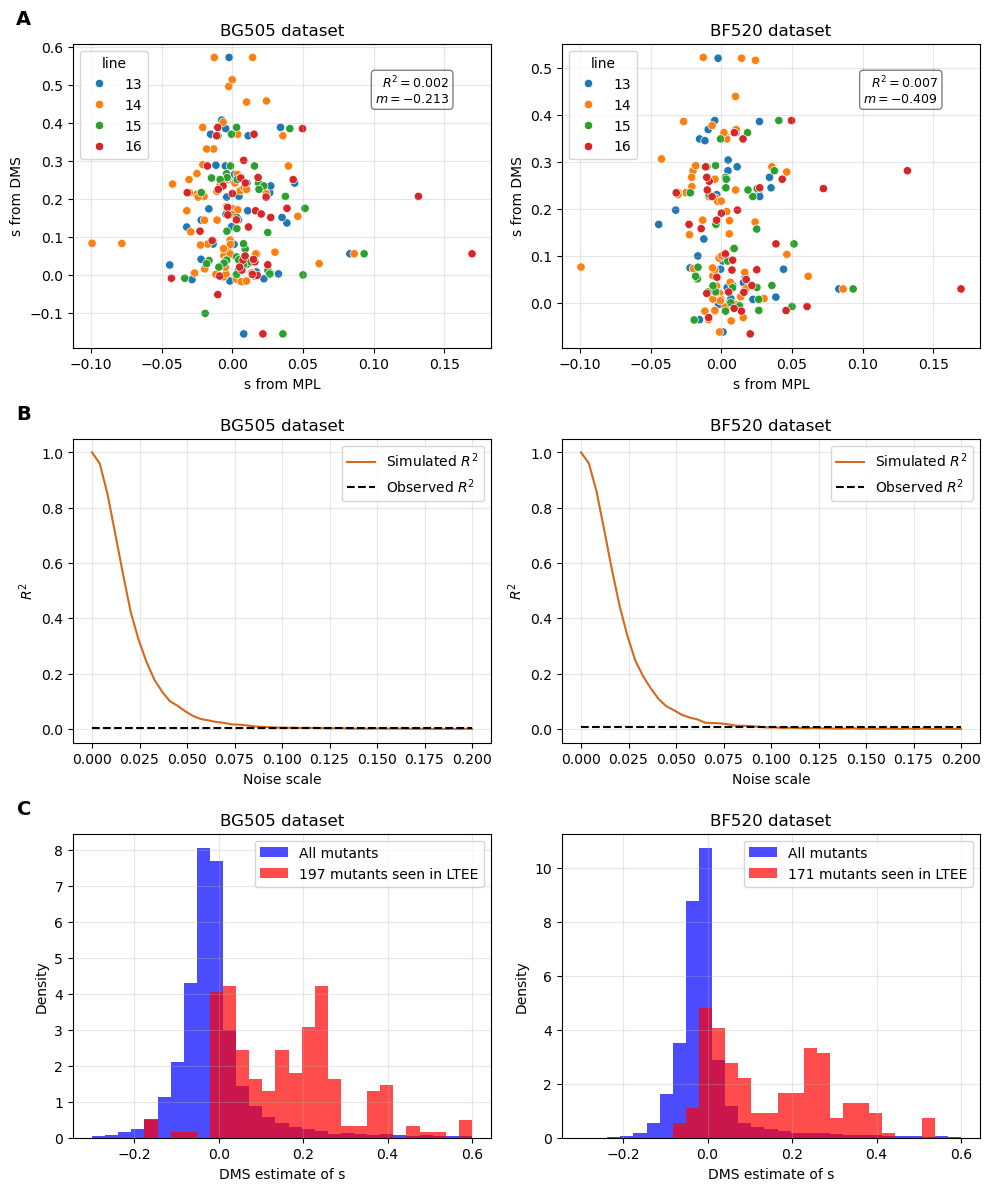

In [24]:
fig, axes = plt.subplots(3,2,figsize=(10,12))

#First row
colours = ['tab:blue','tab:orange','tab:green','tab:red']

sns.scatterplot(data=data_combined_bg, ax=axes[0,0], x='s', y='joint', hue='line',palette=colours)
m, c, r_bg, p, std_err = stats.linregress(data_combined_bg['s'], data_combined_bg['joint'])
axes[0,0].text(0.9, 0.9, f'$R^2 = {r_bg**2:.3f}$\n$m={m:.3f}$', transform=axes[0,0].transAxes, fontsize=9, verticalalignment='top',horizontalalignment='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
axes[0,0].set_title('BG505 dataset')

sns.scatterplot(data=data_combined_bf, ax=axes[0,1], x='s', y='joint', hue='line',palette=colours)
m, c, r_bf, p, std_err = stats.linregress(data_combined_bf['s'], data_combined_bf['joint'])
axes[0,1].text(0.9, 0.9, f'$R^2 = {r_bf**2:.3f}$\n$m={m:.3f}$', transform=axes[0,1].transAxes, fontsize=9, verticalalignment='top',horizontalalignment='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
axes[0,1].set_title('BF520 dataset')

for ax in [axes[0,0],axes[0,1]]:
    ax.set_xlabel('s from MPL')
    ax.set_ylabel('s from DMS')
    

#Second row
axes[1,0].plot(noise, r_bg_noise**2,label='Simulated $R^2$',color='chocolate')
axes[1,0].plot(noise, np.zeros_like(noise) + r_bg**2, '--', color='black',label='Observed $R^2$')
axes[1,0].set_title('BG505 dataset')

axes[1,1].plot(noise, r_bf_noise**2,label='Simulated $R^2$',color='chocolate')
axes[1,1].plot(noise, np.zeros_like(noise) + r_bf**2, '--', color='black',label='Observed $R^2$')
axes[1,1].set_title('BF520 dataset')

for ax in [axes[1,0],axes[1,1]]:
    ax.set_ylabel('$R^2$')
    ax.set_xlabel('Noise scale')
    ax.legend(loc='upper right')


#Third row
axes[2,0].hist(dms_data_bg_all['joint'], bins=np.linspace(-0.3,0.6,30), alpha=0.7, color='blue',density=True,label='All mutants')
axes[2,0].hist(data_combined_bg['joint'], bins=np.linspace(-0.3,0.6,30), alpha=0.7, color='red',density=True,label='197 mutants seen in LTEE')
axes[2,0].set_title('BG505 dataset')

axes[2,1].hist(dms_data_bf_all['joint'], bins=np.linspace(-0.3,0.6,30), alpha=0.7, color='blue',density=True,label='All mutants')
axes[2,1].hist(data_combined_bf['joint'], bins=np.linspace(-0.3,0.6,30), alpha=0.7, color='red',density=True,label='171 mutants seen in LTEE')
axes[2,1].set_title('BF520 dataset')

for ax in [axes[2,0], axes[2,1]]:
    ax.set_xlabel('DMS estimate of s')
    ax.set_ylabel('Density')
    ax.legend()

#Format
for ax in axes.flatten():
    ax.grid(alpha=0.3)

labels = ['A','B','C','D','E','F']
for ax, label in zip([axes[0,0],axes[1,0],axes[2,0]], labels):
    ax.text(-0.1, 1.05, label, transform=ax.transAxes, fontsize=14, fontweight='bold', va='bottom', ha='right')

plt.tight_layout()
plt.savefig(fig_path + f"/Figure_5.pdf")
plt.show()